In [61]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os   # 파일 처리를 위해 사용

In [62]:
# 냥파일 잘 불러왔는지 확인
try:
    cat_files = os.listdir('./data/03_cats_dogs_dataset/cats')
    # 리스트 슬라이싱으로 상위 5개만 확인
    for file_name in cat_files[:5]:
        print(file_name)
except:
    print("냥사진 확인불가: 디렉터리 잘 확인해 보기")

# 댕파일도 똑같은 방식으로 불러오기
try:
    dog_files = os.listdir('./data/03_cats_dogs_dataset/dogs')
    # 상위 5개만 확인
    for file_name in dog_files[:5]:
        print(file_name)
except:
    print("댕사진 확인불가: 디렉터리 잘 확인해 보기")

cat.4001.jpg
cat.4002.jpg
cat.4003.jpg
cat.4004.jpg
cat.4005.jpg
dog.4001.jpg
dog.4002.jpg
dog.4003.jpg
dog.4004.jpg
dog.4005.jpg


In [63]:
# 냥사진과 댕사진 개수는 각각 몇 개일까?
print(len(cat_files), len(dog_files))

1012 1013


In [77]:
# 훈련용 데이터셋 만들기
train_dataset = tf.keras.utils.image_dataset_from_directory(
    './data/03_cats_dogs_dataset/',
    image_size=(64, 64),    # 기존 이미지를 작게 리사이즈, 입력 데이터의 크기를 줄이기
    batch_size=32,      # 이미지 1000개를 한꺼번에 넣지 않고, 32개씩 나누어 넣겠다는 의미
    subset='training',
    validation_split=0.2,
    seed=1234
)


# 검증용 데이터셋 만들기
val_dataset = tf.keras.utils.image_dataset_from_directory(
    './data/03_cats_dogs_dataset/',
    image_size=(64, 64),    
    batch_size=32,  
    subset='validation',
    validation_split=0.2,
    seed=1234   
)


Found 2023 files belonging to 2 classes.
Using 1619 files for training.
Found 2023 files belonging to 2 classes.
Using 404 files for validation.


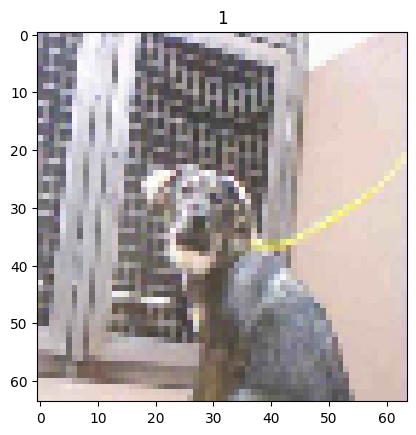

In [78]:
for image, answer in train_dataset.take(1):
    # print(image)
    # print(answer)
    plt.imshow(image[0].numpy().astype("uint8"))  # 첫 번째 이미지
    plt.title(answer[0].numpy())  # 첫 번째 이미지의 정답
    plt.show()

In [82]:
# 모델 빌드
myModel = tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(64, 64, 3)), # 이미지 정규화(0~1)
    tf.keras.layers.Conv2D(32, (3,3), padding='same', activation='relu'),   # 32개의 필터, 3x3 커널
    tf.keras.layers.MaxPooling2D((2, 2)), # 풀링을 통해 데이터 크기 줄이고 특징 남기기
    tf.keras.layers.Conv2D(64, (3,3), padding='same', activation='relu'),   # 64개의 필터
    tf.keras.layers.MaxPooling2D((2, 2)), # 풀링 2트
    tf.keras.layers.Dropout(0.25),   # 과적합 방지
    tf.keras.layers.Conv2D(128, (3,3), padding='same', activation='relu'), # 128개의 필터
    tf.keras.layers.MaxPooling2D((2, 2)), # 풀링 3트
    tf.keras.layers.Dropout(0.5),   # 과적합 방지
    tf.keras.layers.Flatten(),  # 2D 이미지를 1D로 변환
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.25),   # 과적합 방지
    tf.keras.layers.Dense(1, activation='sigmoid') # 이진 분류이므로 1개 출력
])
# 모델 요약
myModel.summary()

Model: "sequential_24"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_24 (Rescaling)    (None, 64, 64, 3)         0         
                                                                 
 conv2d_71 (Conv2D)          (None, 64, 64, 32)        896       
                                                                 
 max_pooling2d_71 (MaxPooli  (None, 32, 32, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_72 (Conv2D)          (None, 32, 32, 64)        18496     
                                                                 
 max_pooling2d_72 (MaxPooli  (None, 16, 16, 64)        0         
 ng2D)                                                           
                                                                 
 dropout_63 (Dropout)        (None, 16, 16, 64)      

In [83]:
# 모델 컴파일
myModel.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
# 모델 훈련
myHistory = myModel.fit(train_dataset,
                        validation_data=val_dataset,
                        epochs=20)


Epoch 1/20


51/51 [==============================] - 2s 31ms/step - loss: 0.6959 - accuracy: 0.5435 - val_loss: 0.6900 - val_accuracy: 0.5198
Epoch 2/20
51/51 [==============================] - 2s 29ms/step - loss: 0.6896 - accuracy: 0.5448 - val_loss: 0.6883 - val_accuracy: 0.5099
Epoch 3/20
51/51 [==============================] - 2s 29ms/step - loss: 0.6785 - accuracy: 0.5757 - val_loss: 0.6813 - val_accuracy: 0.5470
Epoch 4/20
51/51 [==============================] - 2s 29ms/step - loss: 0.6508 - accuracy: 0.6115 - val_loss: 0.6481 - val_accuracy: 0.6287
Epoch 5/20
51/51 [==============================] - 2s 29ms/step - loss: 0.6254 - accuracy: 0.6411 - val_loss: 0.6343 - val_accuracy: 0.6064
Epoch 6/20
51/51 [==============================] - 2s 30ms/step - loss: 0.6050 - accuracy: 0.6720 - val_loss: 0.6189 - val_accuracy: 0.6386
Epoch 7/20
51/51 [==============================] - 2s 29ms/step - loss: 0.5875 - accuracy: 0.6924 - val_loss: 0.6228 - val_accuracy: 0.6213
Epoch 8/20
51/51 [======

Text(0.5, 0, 'Epoch')

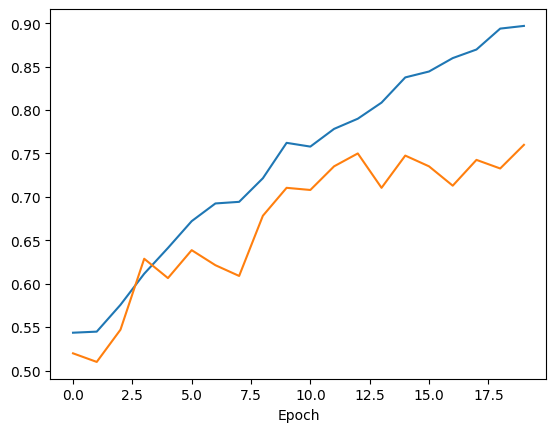

In [84]:
# 훈련 결과 검증
plt.plot(myHistory.history['accuracy'], label='accuracy')
plt.plot(myHistory.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')

In [89]:
# 내 고양이 사진으로 판별해 보자
myImage = tf.keras.utils.load_img('./data/test_cat.png', target_size=(64, 64)) #
myImage = tf.keras.utils.img_to_array(myImage)  # 이미지를 배열로 변환
myImage = myImage / 255.0 # 이미지 정규화

# 모델에 넣기 위해 차원 추가
myImage = tf.expand_dims(myImage, axis=0)

In [93]:
myPredict = myModel.predict(myImage)  
print(myPredict)
if myPredict < 0.5:
    print("냥이입니다.")
else:
    print("댕댕이입니다.")

1/1 [==============================] - 0s 9ms/step
[[0.01166719]]
냥이입니다.
